# Gaussian relabeling

This example creates a two-source trans-dimensional chain, permutes the labels in every sample, and recovers a consistent catalog with the multivariate Gaussian method.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from petra import PosteriorChain, make_catalog_mv_normal

In [2]:
rng = np.random.default_rng(0)
n_samples = 600
chain = np.full((n_samples, 2, 1), np.nan)
chain[:, 0, 0] = rng.normal(-1.0, 0.15, n_samples)
second_source_present = rng.random(n_samples) < 0.65
chain[second_source_present, 1, 0] = rng.normal(
    1.0, 0.15, second_source_present.sum()
)
for sample in chain:
    rng.shuffle(sample, axis=0)

posterior = PosteriorChain(
    chain,
    num_sources=2,
    num_params_per_source=1,
    trans_dimensional=True,
)

In [3]:
result = make_catalog_mv_normal(
    posterior,
    max_num_sources=2,
    num_iterations=10,
    init_num_iterations=10,
    progress=False,
)
expected_probabilities = np.array([1.0, second_source_present.mean()])
np.testing.assert_allclose(
    np.sort(result.prob_in_model), np.sort(expected_probabilities)
)
result.prob_in_model

array([0.63833333, 1.        ])

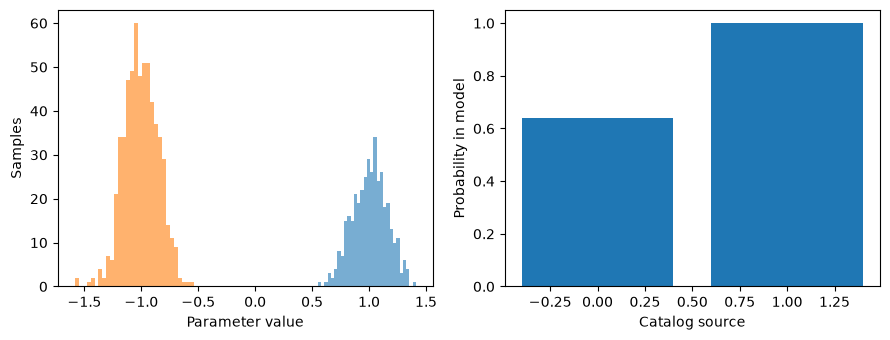

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for source in range(result.num_sources):
    axes[0].hist(result.chain[:, source, 0], bins=30, alpha=0.6)
axes[0].set_xlabel("Parameter value")
axes[0].set_ylabel("Samples")
axes[1].bar(range(len(result.prob_in_model)), result.prob_in_model)
axes[1].set_xlabel("Catalog source")
axes[1].set_ylabel("Probability in model")
fig.tight_layout()
plt.show()